## Q3: Which combinations of customer characteristics and user behavior generate the highest total revenue?

### CRISP-DM Phase 3: Data Preparation

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine

#CRISP-DM Phase 3: Data Preparation
# Load Gold tables
engine = create_engine("trino://admin@trino:8080/iceberg")
df_sales = pd.read_sql("SELECT * FROM iceberg.datamart.fact_sales", con=engine)
df_users = pd.read_sql("SELECT * FROM iceberg.datamart.dim_users", con=engine)

# Link dataframes together via Primary Key user_id
df = pd.merge(df_sales, df_users, on = "user_id")

# Fix inconsistent country domains
# Existing duplicates like Deutschland -> Germany
country_mapping = {'Deutschland': 'Germany', 'España': 'Spain', 'Brasil': 'Brazil'}
df['country'] = df['country'].replace(country_mapping)

# Transforming ages into family life cycle stages
df['age_group'] = pd.cut(
    df['age'], 
    bins = [0, 25, 35, 50, 100], 
    labels = ['Under 25', '25 - 35', '35 - 50', 'Over 50']
    #Categorization: entry in job market, Young Professionals, Family Phase, Older consuments
)
# definition of target measure (Revenue) to ensure code maintainability
revenue_col = 'sale_price'

df.info()
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181759 entries, 0 to 181758
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   order_item_id   181759 non-null  int64              
 1   order_id        181759 non-null  int64              
 2   user_id         181759 non-null  int64              
 3   product_id      181759 non-null  int64              
 4   date_key        181759 non-null  object             
 5   created_at      181759 non-null  datetime64[ns, UTC]
 6   status          181759 non-null  object             
 7   sale_price      181759 non-null  float64            
 8   inventory_cost  181759 non-null  float64            
 9   gross_margin    181759 non-null  float64            
 10  is_returned     181759 non-null  int64              
 11  age             181759 non-null  int64              
 12  gender          181759 non-null  object             
 13  country       

,order_item_id,order_id,user_id,product_id,date_key,created_at,status,sale_price,inventory_cost,gross_margin,is_returned,age,gender,country,state,city,traffic_source,registered_at,age_group
0,112925,77813,62090,25140,2020-03-04,2020-03-04 04:20:30+00:00,Processing,25.0,15.00,10.00,0,33,M,United States,Texas,Lucas,Facebook,2019-03-04 07:33:00+00:00,25 - 35
1,128830,88709,70708,29103,2021-11-19,2021-11-19 01:48:58+00:00,Shipped,25.0,8.77,16.23,0,46,M,United States,Massachusetts,Franklin,Search,2019-04-29 03:03:00+00:00,35 - 50
2,148765,102453,81811,26052,2020-03-01,2020-03-01 03:26:12+00:00,Processing,25.0,12.15,12.85,0,41,M,China,Guangdong,Beijing,Facebook,2019-06-27 07:09:00+00:00,35 - 50
3,151491,104313,83291,6548,2020-03-14,2020-03-14 03:58:58+00:00,Processing,25.0,13.67,11.33,0,60,F,United States,Maryland,Wheaton-Glenmont,Organic,2019-12-15 07:49:00+00:00,Over 50
4,158690,109289,87323,26053,2020-03-23,2020-03-23 13:19:21+00:00,Processing,25.0,10.83,14.17,0,59,M,China,Hebei,Jieyang,Organic,2020-01-05 17:01:00+00:00,Over 50


### Analysis A: Global Revenue Matrix

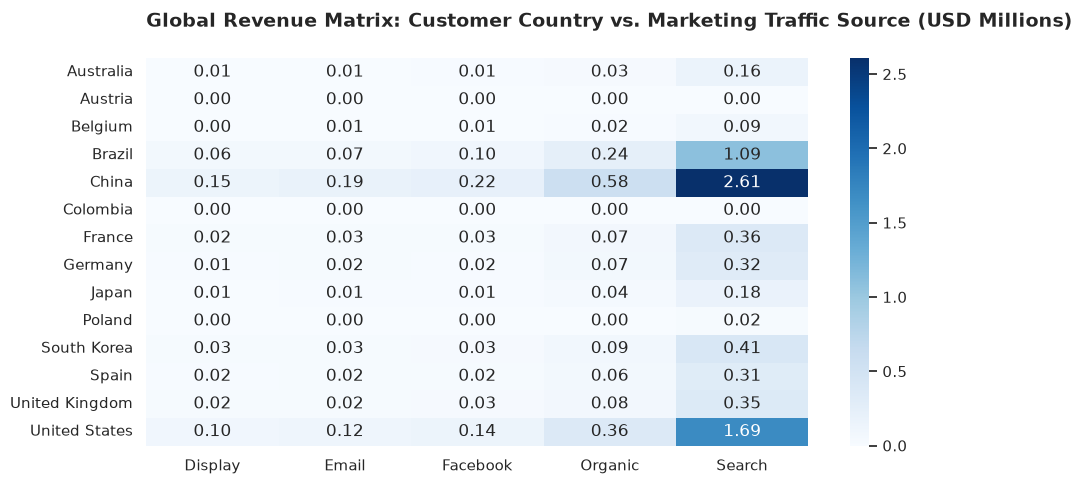

traffic_source,Display,Email,Facebook,Organic,Search
country,,,,,
Australia,0.008095,0.007222,0.010995,0.034429,0.158864
Austria,0.000000,0.000000,0.000010,0.000000,0.000074
Belgium,0.003722,0.006497,0.007395,0.016613,0.091115
Brazil,0.062437,0.066776,0.095696,0.236112,1.093869
China,0.152531,0.189010,0.215500,0.578199,2.605468
Colombia,0.000000,0.000308,0.000243,0.000140,0.000497
France,0.021136,0.026921,0.029417,0.071874,0.357196
Germany,0.014709,0.024420,0.020039,0.070904,0.321915
Japan,0.008826,0.011482,0.013750,0.043210,0.183182


In [3]:
# Multidimensional Pivot Table containing country & traffic
revenue_pivot = pd.pivot_table(
    df, 
    values = revenue_col, 
    index = 'country', 
    columns = 'traffic_source', 
    aggfunc = 'sum',
    fill_value = 0
)

# compressing digits to millions for text clarity
revenue_pivot_mil = revenue_pivot / 1_000_000

# Generating IBCS Compliant Matrix
plt.figure(figsize = (10, 5))
sns.set_theme(style = "white") # Removes decorative gridlines

ax_matrix = sns.heatmap(
    revenue_pivot_mil, 
    annot = True,             # displays values on elements
    fmt = ".2f",              # Limiting layout to max. 4 digits
    cmap = "Blues",           
)

#Delete ax labels
ax_matrix.set_xlabel('')
ax_matrix.set_ylabel('')
plt.title('Global Revenue Matrix: Customer Country vs. Marketing Traffic Source (USD Millions) \n', 
          fontsize = 14, fontweight = 'bold', loc = 'left')

plt.tight_layout()
plt.savefig('customer_characteristics_behavior.png', dpi = 300) #save as picture
plt.show()
revenue_pivot_mil

### Analysis B: Top 10 Customer Segments

In [4]:
# Create MultiIndex object with group by
analysis = df.groupby(['age_group', 'gender', 'traffic_source'], observed=False).agg({'sale_price': 'sum'})
print(analysis.head(5))

                                 sale_price
age_group gender traffic_source            
Under 25  F      Display           53562.38
                 Email             58944.96
                 Facebook          65269.00
                 Organic          175721.04
                 Search           828435.29


In [5]:
# Flattening MultiIndex structure back to standard DataFrame
analysis = analysis.reset_index()

# Sorting along revenue axis to build ranking
analysis = analysis.sort_values(by = 'sale_price', ascending=False).reset_index(drop=True)
analysis['Customer_Segment'] = analysis['traffic_source'] + " | " + analysis['age_group'].astype(str) + " | " + analysis['gender'] 

print(analysis[['Customer_Segment', 'sale_price']].head(10))

        Customer_Segment  sale_price
0   Search | Over 50 | M  1388724.49
1   Search | Over 50 | F  1229258.69
2   Search | 35 - 50 | M   998893.44
3  Search | Under 25 | M   972225.09
4   Search | 35 - 50 | F   903664.78
5  Search | Under 25 | F   828435.29
6   Search | 25 - 35 | M   663020.39
7   Search | 25 - 35 | F   613020.41
8  Organic | Over 50 | M   287926.00
9  Organic | Over 50 | F   254766.23


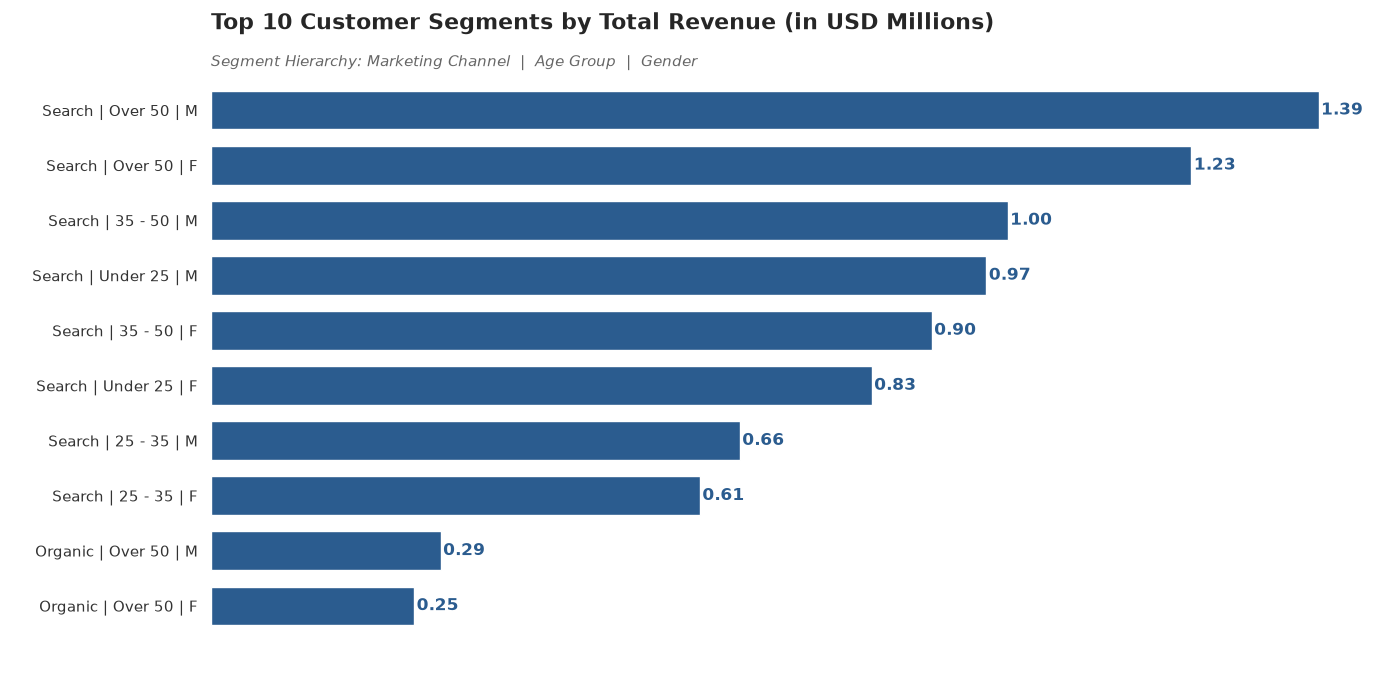

In [6]:
# top_10 for Evaluation
top_10 = analysis.head(10).copy()

# Initializing structure of figure and axes 
fig, ax = plt.subplots(figsize=(14, 7), dpi=100, tight_layout=False)

# Render horizontal structure bars
y_positions = range(len(top_10)) 
ax.barh(y_positions, top_10['sale_price'], color = '#2b5c8f', height = 0.7)
ax.set_yticks(y_positions)
ax.set_yticklabels(top_10['Customer_Segment'], fontsize=11, fontweight='normal', color='#333333')
ax.set_title('Top 10 Customer Segments by Total Revenue (in USD Millions)\n', fontsize = 16, fontweight = 'bold', loc = 'left')
ax.text(0, -0.8, 'Segment Hierarchy: Marketing Channel  |  Age Group  |  Gender', fontsize=11, fontstyle='italic', color='#666666', transform=ax.get_yaxis_transform())
ax.set_xlabel(" ")
ax.set_ylabel(" ")

# Applying IBCS rules
ax.set_frame_on(False) 
ax.tick_params(left=False, labelleft=True, bottom=False, labelbottom=False)


x_values = top_10['sale_price']
# Labeling loop for bars 
for y_val, x_val in zip(y_positions, x_values):
    revenue_in_millions = x_val / 1_000_000
    
    ax.text(
        x_val + 3000, #bar gap
        y_val, 
        f"{revenue_in_millions:.2f}", 
        va = 'center', 
        ha = 'left', 
        fontsize = 12, 
        fontweight = 'bold', 
        color = '#2b5c8f'
    )

ax.invert_yaxis() 

plt.tight_layout()
plt.savefig('top_segments.png', dpi=300) #safe as picture
plt.show()